<a href="https://colab.research.google.com/github/nahushdeshmukh17/GenerativeAI-NN/blob/main/PlantVillage_CNN_vs_ResNet50_RAM_Safe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PlantVillage Image Classification — CNN vs ResNet50

**Pipeline:** PlantVillage → stratified 80/10/10 split → RAM-safe `tf.data` pipeline → CNN from scratch → pretrained ResNet50 → fine-tuning → final test comparison.

**Important:** Test data is used only for final evaluation. Models and training backups are stored persistently so a runtime disconnect does not force a full restart.


### Project Overview: PlantVillage Image Classification

This project aims to classify plant diseases using image data from the PlantVillage dataset, comparing the performance of a custom Convolutional Neural Network (CNN) against a ResNet50 model leveraging transfer learning. The pipeline is designed for robustness and efficient resource utilization.

**Key Steps and Features:**

*   **Dataset Acquisition:** The PlantVillage dataset is automatically downloaded and prepared.
*   **Data Splitting:** A stratified 80/10/10 split is performed for training, validation, and testing to ensure representative data distribution across classes.
*   **RAM-safe Data Pipeline:** `tf.data` is used to create an efficient and memory-conscious input pipeline, especially crucial for large image datasets.
*   **Image Preprocessing & Augmentation:** Images are resized, converted to RGB, normalized, and augmented with techniques like horizontal flips, rotations, zooms, and translations to improve model generalization.
*   **Model Development:**
    *   **Custom CNN:** A Convolutional Neural Network is built from scratch with multiple `Conv2D` and `MaxPooling2D` layers, followed by `GlobalAveragePooling2D`, `Dense` layers, and `Dropout`.
    *   **ResNet50 Transfer Learning:** A pre-trained ResNet50 model (on ImageNet) is used as a feature extractor (`include_top=False`). A new classification head is added on top. The base model's weights are initially frozen and then fine-tuned for better performance.
*   **Persistent Training & Recovery:** Models and training backups are saved persistently, allowing for recovery and continuation of training even after runtime disconnections.
*   **Evaluation:** Both models are evaluated on a separate test set using metrics such as accuracy, precision, recall, and F1-score. Confusion matrices are also generated.
*   **Model Comparison:** A visual comparison of the performance metrics between the custom CNN and the fine-tuned ResNet50 model is provided to highlight their respective strengths.

             
# Architecture            
            
            
                         ┌───────────────────────┐
                         │   PlantVillage       │
                         │      Dataset         │
                         └───────────┬───────────┘
                                     │
                                     ▼
                         ┌───────────────────────┐
                         │   Image Preprocessing │
                         │                       │
                         │ • Resize → 224×224   │
                         │ • RGB conversion     │
                         │ • Normalization      │
                         └───────────┬───────────┘
                                     │
                                     ▼
                         ┌───────────────────────┐
                         │   Data Augmentation   │
                         │                       │
                         │ • Horizontal Flip    │
                         │ • Rotation            │
                         │ • Zoom                │
                         │ • Translation         │
                         └───────────┬───────────┘
                                     │
                                     ▼
                         ┌───────────────────────┐
                         │   Dataset Splitting   │
                         │                       │
                         │ Train: 80%            │
                         │ Validation: 10%       │
                         │ Test: 10%              │
                         └───────────┬───────────┘
                                     │
                      ┌──────────────┴──────────────┐
                      │                             │
                      ▼                             ▼
          ┌─────────────────────┐       ┌────────────────────────┐
          │   CUSTOM CNN        │       │      RESNET50          │
          │   From Scratch      │       │   Transfer Learning    │
          └──────────┬──────────┘       └────────────┬───────────┘
                     │                               │
                     ▼                               ▼
          ┌─────────────────────┐       ┌────────────────────────┐
          │ Conv2D – 32         │       │ ResNet50 Backbone      │
          │ MaxPooling          │       │ ImageNet Pretrained    │
          │ Conv2D – 64         │       │        ↓               │
          │ MaxPooling          │       │ Freeze Backbone        │
          │ Conv2D – 128        │       │        ↓               │
          │ MaxPooling          │       │ Train Classification   │
          │ Conv2D – 256        │       │ Head                   │
          │ MaxPooling          │       └────────────┬───────────┘
          └──────────┬──────────┘                    │
                     │                               ▼
                     │                    ┌───────────────────────┐
                     │                    │ Fine-Tuning           │
                     │                    │                       │
                     │                    │ Unfreeze last ~30     │
                     │                    │ layers + low LR       │
                     │                    └───────────┬───────────┘
                     │                                │
                     └──────────────┬─────────────────┘
                                    ▼
                         ┌───────────────────────┐
                         │   Classification      │
                         │                       │
                         │ Dense + Softmax       │
                         │ Plant Disease Classes │
                         └───────────┬───────────┘
                                     │
                                     ▼
                         ┌───────────────────────┐
                         │      Evaluation       │
                         │                       │
                         │ • Accuracy            │
                         │ • Precision           │
                         │ • Recall              │
                         │ • F1-Score            │
                         │ • Confusion Matrix    │
                         └───────────┬───────────┘
                                     │
                                     ▼
                         ┌───────────────────────┐
                         │   CNN vs ResNet50     │
                         │      Comparison       │
                         └───────────────────────┘

In [1]:
# 1. Setup, imports and persistent storage

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from tensorflow.keras import layers, models

# Use Google Drive in Colab; use the current folder on a local PC.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT_DIR = "/content/drive/MyDrive/PlantVillage_Project"
    DATA_DIR = "/content"
except ImportError:
    ROOT_DIR = os.path.abspath("./PlantVillage_Project")
    DATA_DIR = os.getcwd()

MODEL_DIR = os.path.join(ROOT_DIR, "models")
BACKUP_DIR = os.path.join(ROOT_DIR, "training_backups")
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(BACKUP_DIR, exist_ok=True)

# Conservative memory settings: avoid TensorFlow creating excessive GPU memory usage.
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("GPU:", gpus)
print("Model directory:", MODEL_DIR)


Mounted at /content/drive
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Model directory: /content/drive/MyDrive/PlantVillage_Project/models


In [2]:
# 2. Dataset — downloaded automatically if missing

dataset_path = os.path.join(DATA_DIR, "PlantVillage-Dataset", "raw", "color")

if not os.path.exists(dataset_path):
    print("Downloading PlantVillage dataset...")
    !git clone -q https://github.com/spMohanty/PlantVillage-Dataset.git "{os.path.join(DATA_DIR, 'PlantVillage-Dataset')}"
else:
    print("PlantVillage dataset already exists.")

class_names = sorted([
    d.name for d in Path(dataset_path).iterdir() if d.is_dir()
])

print("Classes:", len(class_names))
print("First 5:", class_names[:5])


Classes: 38
First 5: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [3]:
# 3. Stratified Train / Validation / Test split

files = np.array([
    str(p) for p in Path(dataset_path).rglob("*.JPG")
])

labels = np.array([
    class_names.index(Path(f).parent.name)
    for f in files
])

train_files, temp_files, train_labels, temp_labels = train_test_split(
    files, labels,
    test_size=0.20,
    stratify=labels,
    random_state=42
)

val_files, test_files, val_labels, test_labels = train_test_split(
    temp_files, temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

print("Train:", len(train_files))
print("Validation:", len(val_files))
print("Test:", len(test_files))


Train: 42242
Validation: 5280
Test: 5281


In [4]:
# 4. Create RAM-safe TensorFlow datasets

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_images(files, labels):
    ds = tf.data.Dataset.from_tensor_slices((files, labels))

    def load(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_jpeg(image, channels=3)
        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32)
        return image, label

    # Small, controlled parallelism prevents RAM spikes.
    return ds.map(load, num_parallel_calls=2)

train_raw = load_images(train_files, train_labels)
val_raw = load_images(val_files, val_labels)
test_raw = load_images(test_files, test_labels)

print("Raw datasets created.")


Raw datasets created.


In [5]:
# 5. RAM-safe augmentation and input pipeline

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
])

# IMPORTANT: Do not cache() the decoded images.
# Keep shuffle buffer and prefetch small to prevent system-RAM exhaustion.

train_ds = (
    train_raw
    .shuffle(2048, seed=42, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(
        lambda x, y: (data_augmentation(x, training=True), y),
        num_parallel_calls=2
    )
    .prefetch(1)
)

val_ds = val_raw.batch(BATCH_SIZE).prefetch(1)
test_ds = test_raw.batch(BATCH_SIZE).prefetch(1)

print("RAM-safe pipeline ready.")


RAM-safe pipeline ready.


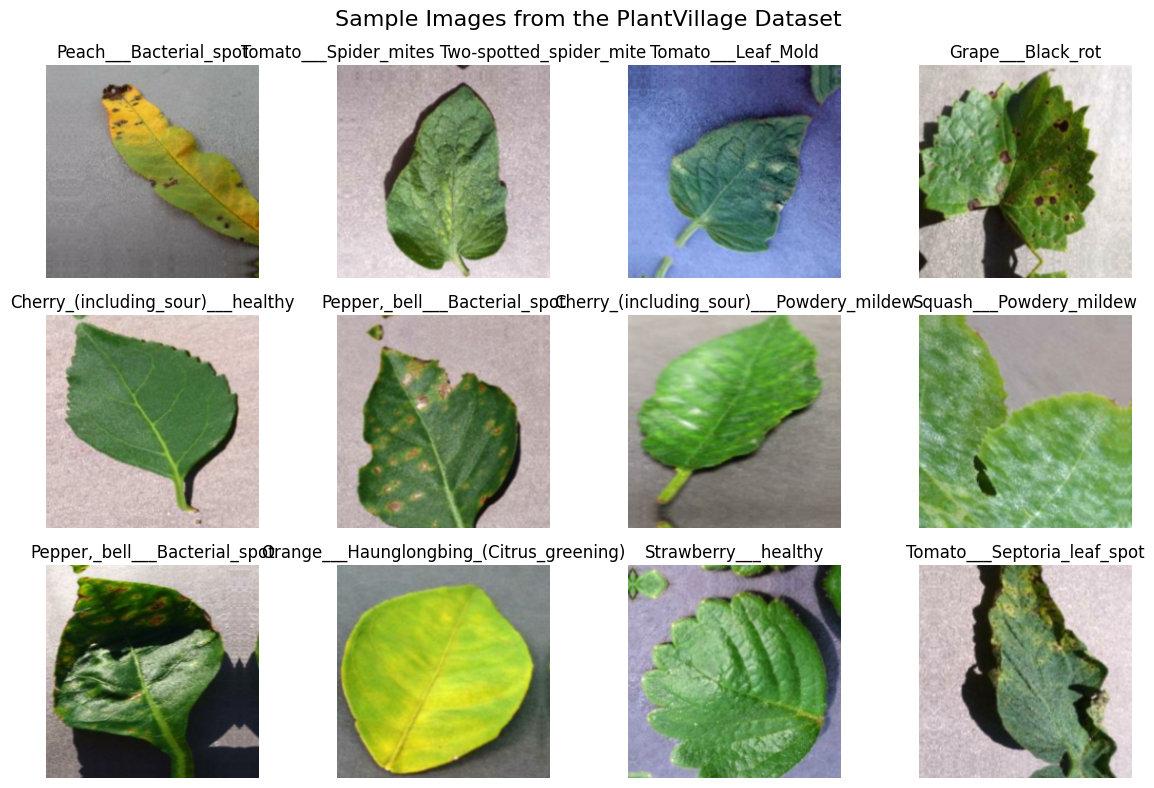

Number of classes: 38
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_sp

In [17]:
# 5.5. Dataset Sample Visualization

import matplotlib.pyplot as plt
import numpy as np

# Get one batch from training dataset
images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(min(12, len(images))):
    plt.subplot(3, 4, i + 1)

    # Display image
    img = images[i].numpy()

    # Normalize for visualization if needed
    img = img - img.min()
    img = img / (img.max() + 1e-8)

    plt.imshow(img)
    plt.title(class_names[int(labels[i])])
    plt.axis("off")

plt.suptitle("Sample Images from the PlantVillage Dataset", fontsize=16)
plt.tight_layout()
plt.show()

print("Number of classes:", len(class_names))
print("Classes:", class_names)

In [ ]:
# 6. CNN from scratch

cnn = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax", dtype="float32")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 463,974 (1.77 MB)

 Trainable params: 463,974 (1.77 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 7. Train CNN with persistent checkpoint + restart recovery

cnn_best = os.path.join(MODEL_DIR, "cnn_best.keras")
cnn_backup = os.path.join(BACKUP_DIR, "cnn")

cnn_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    cnn_best,
    monitor="val_loss",
    save_best_only=True
)

cnn_backup_cb = tf.keras.callbacks.BackupAndRestore(
    backup_dir=cnn_backup
)

cnn_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

if os.path.exists(cnn_best):
    print("Best CNN already exists. Loading it instead of retraining.")
    cnn = tf.keras.models.load_model(cnn_best)
    history_cnn = None
else:
    history_cnn = cnn.fit(
        train_ds,
        validation_data=val_ds,
        epochs=8,
        callbacks=[cnn_backup_cb, cnn_checkpoint, cnn_early_stop]
    )


Epoch 1/8
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 584s 433ms/step - accuracy: 0.4022 - loss: 2.2111 - val_accuracy: 0.6119 - val_loss: 1.3443
Epoch 2/8
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 586s 441ms/step - accuracy: 0.6741 - loss: 1.0973 - val_accuracy: 0.7659 - val_loss: 0.7755
Epoch 3/8
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 550s 415ms/step - accuracy: 0.7689 - loss: 0.7615 - val_accuracy: 0.7585 - val_loss: 0.8037
Epoch 4/8
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 559s 420ms/step - accuracy: 0.8248 - loss: 0.5756 - val_accuracy: 0.8680 - val_loss: 0.4273
Epoch 5/8
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 548s 413ms/step - accuracy: 0.8567 - loss: 0.4662 - val_accuracy: 0.9148 - val_loss: 0.2756
Epoch 6/8
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 549s 414ms/step - accuracy: 0.8805 - loss: 0.3852 - val_accuracy: 0.8991 - val_loss: 0.3503
Epoch 7/8
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 554s 418ms/step - accuracy: 0.8944 - loss: 0.3440 - val_accuracy: 0.9309 - val_loss: 0.2218
Epoch 8/8
1321/1321 ━━━━━━━━━━━━━━━━━━━━ 554s 418ms/step - accuracy: 

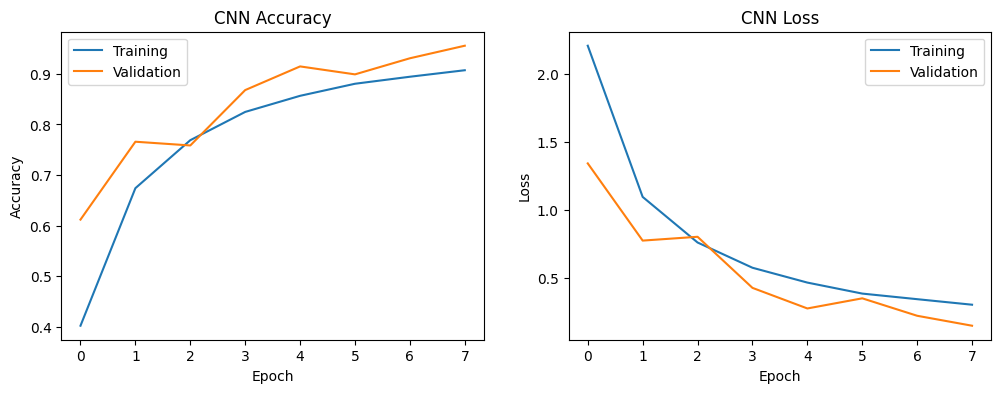

In [ ]:
# 8. CNN training curves

if history_cnn is not None:
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history_cnn.history["accuracy"], label="Training")
    plt.plot(history_cnn.history["val_accuracy"], label="Validation")
    plt.title("CNN Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history_cnn.history["loss"], label="Training")
    plt.plot(history_cnn.history["val_loss"], label="Validation")
    plt.title("CNN Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.show()
else:
    print("CNN was loaded from the persistent checkpoint; no new training curves were generated.")


In [ ]:
# 9. Create true labels for final evaluation

y_true = np.concatenate([
    y.numpy() for _, y in test_ds
])

print("y_true created successfully.")
print("Number of test samples:", len(y_true))

y_true created successfully.
Number of test samples: 5281


In [10]:
# 9. Final CNN test evaluation

# Define CNN model path again after runtime reconnection
cnn_best = os.path.join(MODEL_DIR, "cnn_best.keras")

cnn = tf.keras.models.load_model(cnn_best)

y_true = np.concatenate([y.numpy() for _, y in test_ds])

cnn_prob = cnn.predict(test_ds)
cnn_pred = np.argmax(cnn_prob, axis=1)

print("CNN evaluation data created successfully.")
print("Test samples:", len(y_true))

166/166 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step
CNN evaluation data created successfully.
Test samples: 5281


In [6]:
# 10. ResNet50 transfer learning model

base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

resnet = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Lambda(tf.keras.applications.resnet50.preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax", dtype="float32")
])

resnet.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,122,022 (92.02 MB)

 Trainable params: 534,310 (2.04 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [7]:
# 11. Load saved ResNet50 head model

resnet_best = os.path.join(MODEL_DIR, "resnet_best.keras")
resnet_backup = os.path.join(BACKUP_DIR, "resnet_head")

from tensorflow.keras.applications.resnet50 import preprocess_input

if os.path.exists(resnet_best):
    print("Saved ResNet50 found. Loading...")

    resnet = tf.keras.models.load_model(
        resnet_best,
        custom_objects={"preprocess_input": preprocess_input}
    )

    print("ResNet50 model loaded successfully.")
else:
    print("No saved ResNet50 model found.")

Saved ResNet50 found. Loading...
ResNet50 model loaded successfully.


In [14]:
# 12. Fine-tune last ResNet50 layers — persistent recovery

resnet_best = os.path.join(MODEL_DIR, "resnet_best.keras")

# Load saved ResNet50
if os.path.exists(resnet_best):
    resnet = tf.keras.models.load_model(
        resnet_best,
        custom_objects={"preprocess_input": preprocess_input}
    )
    print("Loaded saved ResNet50 model.")

# Get ResNet50 base
base_model = resnet.get_layer("resnet50")
base_model.trainable = True

# Freeze all except last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Compile
resnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Paths
finetuned_best = os.path.join(
    MODEL_DIR, "resnet_finetuned_best.keras"
)

finetune_backup = os.path.join(
    BACKUP_DIR, "resnet_finetune"
)

# Callbacks
finetune_backup_cb = tf.keras.callbacks.BackupAndRestore(
    backup_dir=finetune_backup
)

finetune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    finetuned_best,
    monitor="val_loss",
    save_best_only=True
)

finetune_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train or load existing fine-tuned model
if os.path.exists(finetuned_best):

    print("Fine-tuned ResNet50 already exists. Loading it.")

    resnet = tf.keras.models.load_model(
        finetuned_best,
        custom_objects={"preprocess_input": preprocess_input}
    )

    history_finetune = None

else:

    history_finetune = resnet.fit(
        train_ds,
        validation_data=val_ds,
        epochs=3,
        callbacks=[
            finetune_backup_cb,
            finetune_checkpoint,
            finetune_early_stop
        ]
    )

    print("ResNet50 fine-tuning completed.")

Loaded saved ResNet50 model.
Fine-tuned ResNet50 already exists. Loading it.


In [11]:
# 13. Final ResNet50 test evaluation

final_resnet_path = os.path.join(
    MODEL_DIR, "resnet_finetuned_best.keras"
)

from tensorflow.keras.applications.resnet50 import preprocess_input

if os.path.exists(final_resnet_path):
    resnet = tf.keras.models.load_model(
        final_resnet_path,
        custom_objects={"preprocess_input": preprocess_input}
    )
else:
    resnet = tf.keras.models.load_model(
        resnet_best,
        custom_objects={"preprocess_input": preprocess_input}
    )

resnet_prob = resnet.predict(test_ds, verbose=1)
resnet_pred = np.argmax(resnet_prob, axis=1)

resnet_accuracy = accuracy_score(y_true, resnet_pred)
resnet_precision = precision_score(
    y_true, resnet_pred, average="macro", zero_division=0
)
resnet_recall = recall_score(
    y_true, resnet_pred, average="macro", zero_division=0
)
resnet_f1 = f1_score(
    y_true, resnet_pred, average="macro", zero_division=0
)

print("ResNet50 Accuracy :", resnet_accuracy)
print("ResNet50 Precision:", resnet_precision)
print("ResNet50 Recall   :", resnet_recall)
print("ResNet50 F1 Score :", resnet_f1)

166/166 ━━━━━━━━━━━━━━━━━━━━ 25s 117ms/step
ResNet50 Accuracy : 0.9808748343116834
ResNet50 Precision: 0.9797695696440619
ResNet50 Recall   : 0.9743128931956262
ResNet50 F1 Score : 0.9764629589206313


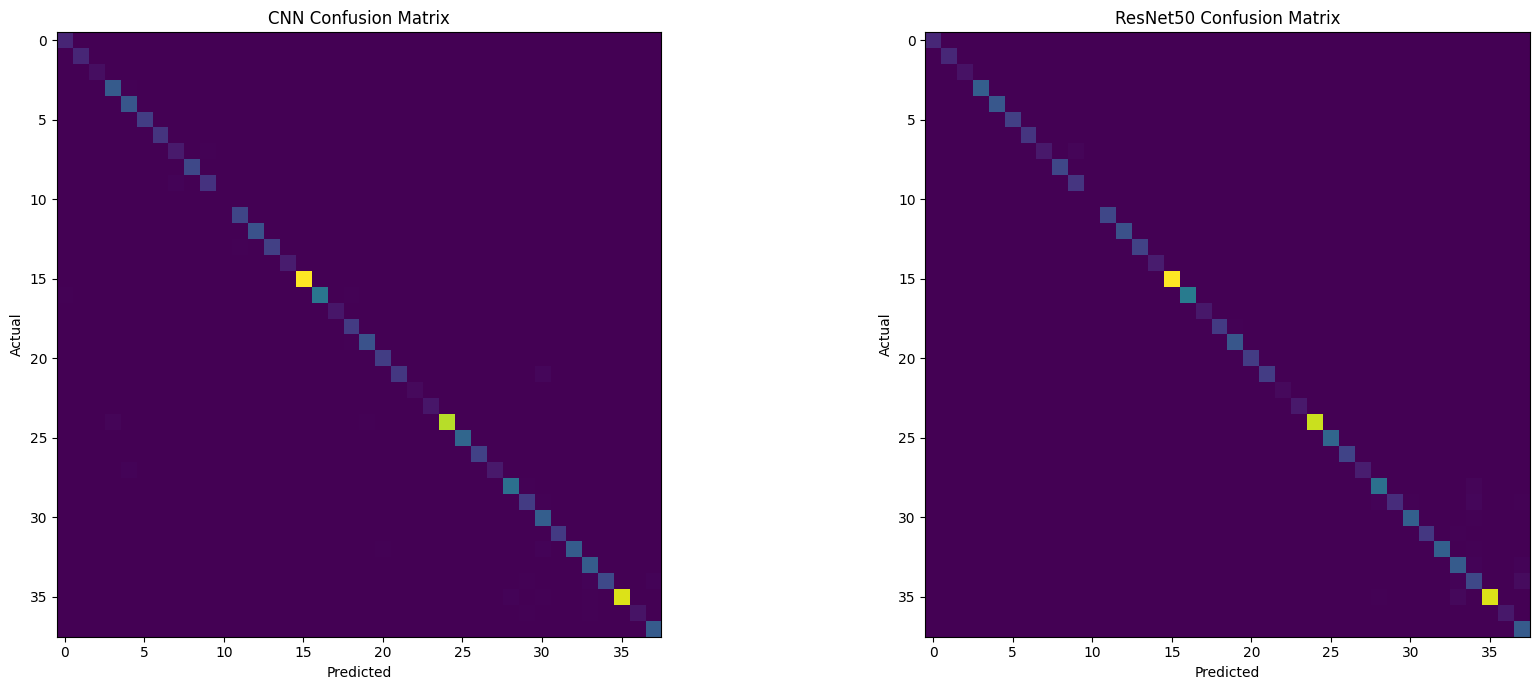

In [ ]:
# 14. Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].imshow(confusion_matrix(y_true, cnn_pred))
axes[0].set_title("CNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

axes[1].imshow(confusion_matrix(y_true, resnet_pred))
axes[1].set_title("ResNet50 Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [12]:
# 15. Final CNN vs ResNet50 comparison

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# True labels
y_true = np.concatenate([y.numpy() for _, y in test_ds]).astype(int).flatten()

# CNN predictions
cnn_prob = cnn.predict(test_ds, verbose=1)
cnn_pred = np.argmax(cnn_prob, axis=1)

# ResNet50 predictions
resnet_prob = resnet.predict(test_ds, verbose=1)
resnet_pred = np.argmax(resnet_prob, axis=1)

# Metrics
cnn_accuracy = accuracy_score(y_true, cnn_pred)
cnn_precision = precision_score(y_true, cnn_pred, average="macro", zero_division=0)
cnn_recall = recall_score(y_true, cnn_pred, average="macro", zero_division=0)
cnn_f1 = f1_score(y_true, cnn_pred, average="macro", zero_division=0)

resnet_accuracy = accuracy_score(y_true, resnet_pred)
resnet_precision = precision_score(y_true, resnet_pred, average="macro", zero_division=0)
resnet_recall = recall_score(y_true, resnet_pred, average="macro", zero_division=0)
resnet_f1 = f1_score(y_true, resnet_pred, average="macro", zero_division=0)

# Display results
print("\nMetric              CNN     ResNet50")
print("------------------------------------")
print(f"Accuracy         {cnn_accuracy:>7.4f}    {resnet_accuracy:>7.4f}")
print(f"Precision        {cnn_precision:>7.4f}    {resnet_precision:>7.4f}")
print(f"Recall           {cnn_recall:>7.4f}    {resnet_recall:>7.4f}")
print(f"F1-Score         {cnn_f1:>7.4f}    {resnet_f1:>7.4f}")

166/166 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step
166/166 ━━━━━━━━━━━━━━━━━━━━ 13s 81ms/step

Metric              CNN     ResNet50
------------------------------------
Accuracy          0.9627     0.9809
Precision         0.9505     0.9798
Recall            0.9368     0.9743
F1-Score          0.9404     0.9765


In [15]:
# 16. ResNet50 Fine-tuning Curves

if 'history_finetune' not in globals() or history_finetune is None:
    print("ResNet50 training history is not available in this runtime.")
    print("The model was restored from the saved checkpoint, so no new training curve can be reconstructed.")
else:
    plt.figure(figsize=(12, 4))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history_finetune.history["accuracy"], label="Training")
    plt.plot(history_finetune.history["val_accuracy"], label="Validation")
    plt.title("ResNet50 Training vs Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history_finetune.history["loss"], label="Training")
    plt.plot(history_finetune.history["val_loss"], label="Validation")
    plt.title("ResNet50 Training vs Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

ResNet50 training history is not available in this runtime.
The model was restored from the saved checkpoint, so no new training curve can be reconstructed.


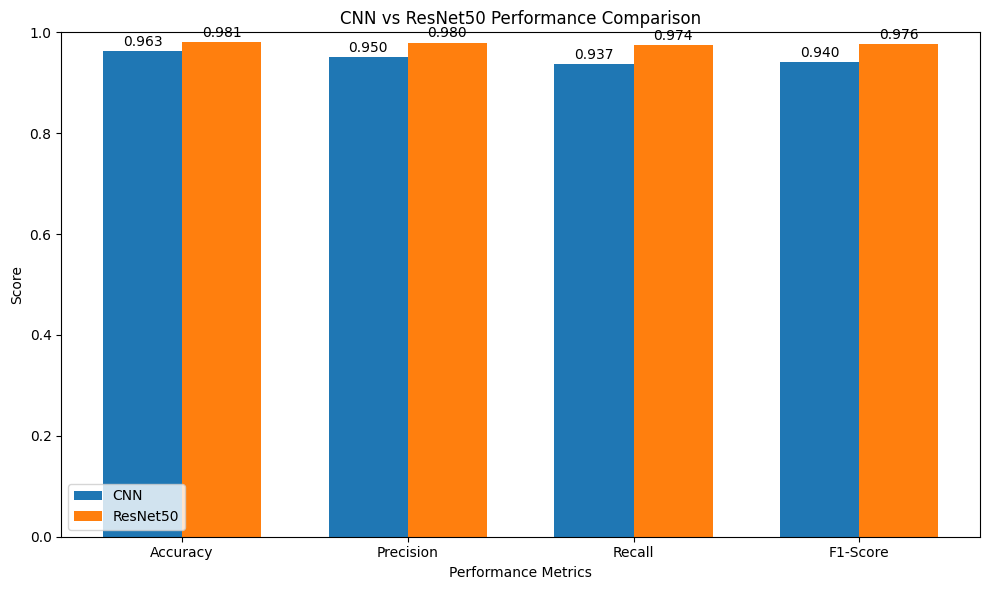

In [16]:
# 17. CNN vs ResNet50 Visual Comparison

import numpy as np
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

cnn_values = [
    cnn_accuracy,
    cnn_precision,
    cnn_recall,
    cnn_f1
]

resnet_values = [
    resnet_accuracy,
    resnet_precision,
    resnet_recall,
    resnet_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(x - width/2, cnn_values, width, label="CNN")
bars2 = plt.bar(x + width/2, resnet_values, width, label="ResNet50")

plt.ylabel("Score")
plt.xlabel("Performance Metrics")
plt.title("CNN vs ResNet50 Performance Comparison")
plt.xticks(x, metrics)
plt.ylim(0, 1.0)
plt.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f"{bar.get_height():.3f}",
            ha="center"
        )

plt.tight_layout()
plt.show()